In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch.nn as nn
from torch.utils.data import DataLoader,Dataset
import torch.optim as optim
import matplotlib.pyplot as plt
import torch

In [ ]:
torch.manual_seed(42)

In [ ]:
device = torch.device('cuda')
torch.cuda.is_available()

True

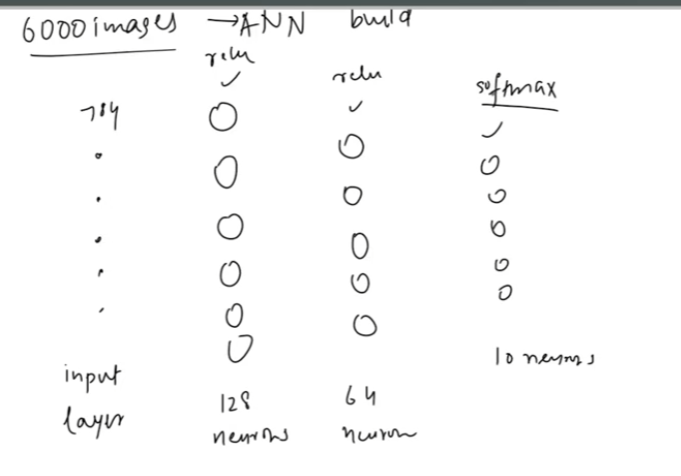

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zalando-research/fashionmnist")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fashionmnist' dataset.
Path to dataset files: /kaggle/input/fashionmnist


In [ ]:
import shutil

destination = "/content/FashionMNIST"

shutil.copytree(path, destination, dirs_exist_ok=True)

print("Dataset saved to Google Drive:", destination)

Dataset saved to Google Drive: /content/FashionMNIST


In [ ]:
df = pd.read_csv('/content/FashionMNIST/fashion-mnist_train.csv')

In [ ]:
df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [ ]:

df.shape

(60000, 785)

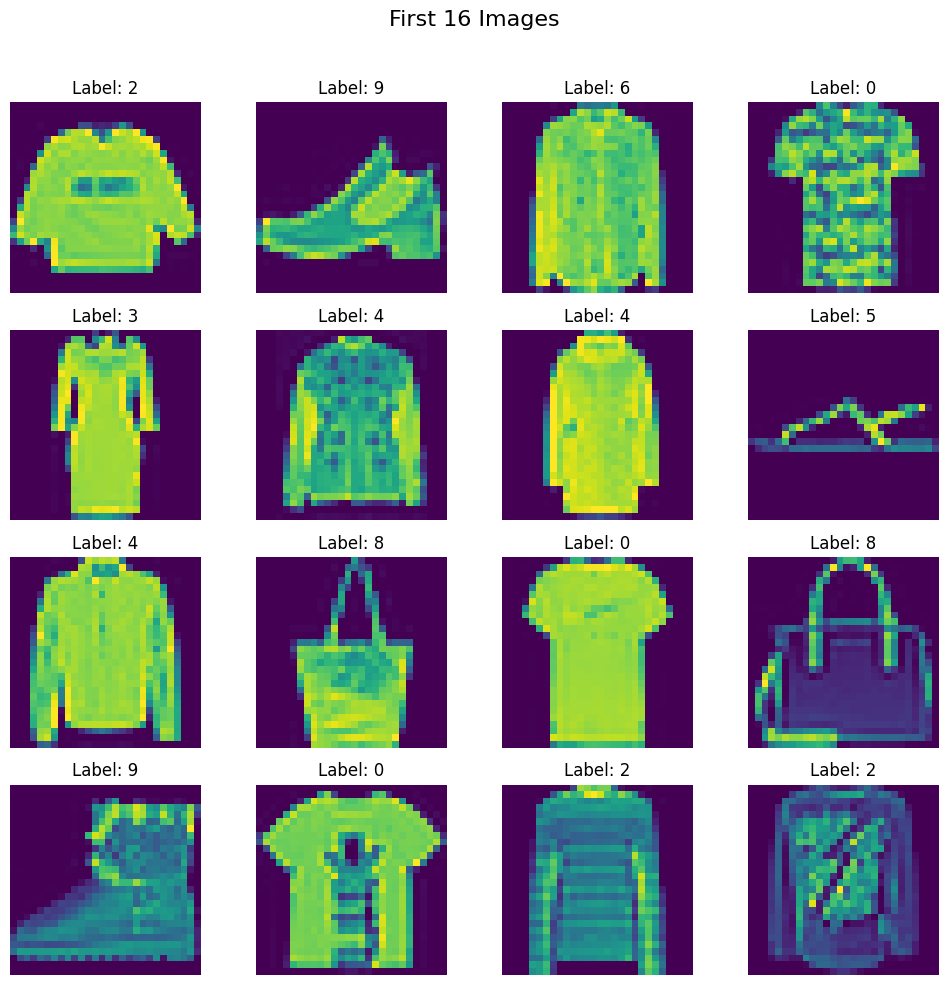

In [ ]:
# Create a 4x4 grid of images
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle("First 16 Images", fontsize=16)

# Plot the first 16 images from the dataset
for i, ax in enumerate(axes.flat):
    img = df.iloc[i, 1:].values.reshape(28, 28)  # Reshape to 28x28
    ax.imshow(img)  # Display in grayscale
    ax.axis('off')  # Remove axis for a cleaner look
    ax.set_title(f"Label: {df.iloc[i, 0]}")  # Show the label

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to fit the title
plt.show()


In [ ]:
x = df.iloc[:,1:].values
y = df.iloc[:,0:1].values

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [ ]:
x_train.shape

(48000, 784)

In [ ]:
# feature scalling
x_train = x_train/255.0
x_test = x_test/255.0

# The Class Declaration: class customDataset(Dataset):

• What it does: This defines your new dataset type.
• The parent (Dataset): This tells Python that your class inherits from PyTorch's built-in Dataset utility. By doing this, your custom dataset automatically becomes compatible with PyTorch's DataLoader (which handles shuffling, batching, and multiprocessing for your model).


# 1. The Initialization Function: __init__(self, features, leables):

• Purpose: This function runs automatically the exact moment you create your dataset (e.g., when you write dataset = customDataset(X, y)). It acts as the setup manager.
• self.features = torch.tensor(...): It takes your raw input data (like images, text arrays, or numbers) and converts them into a PyTorch Float32 Tensor so the neural network can run math calculations on it.
• self.leables = torch.tensor(...): It takes your target answers (labels) and converts them into a PyTorch Long Tensor (integers). This is the standard data type PyTorch expects for classification categories.

# 2. The Length Function: __len__(self):

• Purpose: This tells PyTorch exactly how many items are inside your dataset.

# 3. The Item Retrieval Function: __getitem__(self, index):

• Purpose: This allows you to pull out a single data point and its matching label using an index number (e.g., dataset[5]).

In [ ]:
# create a customDataset class
class customDataset(Dataset):
  def __init__(self, features, leables):
    self.features = torch.tensor(features, dtype = torch.float32)
    self.leables = torch.tensor(leables, dtype = torch.long)

  def __len__(self):
    return len(self.features)

  def __getitem__(self, index):
    return self.features[index], self.leables[index]

In [ ]:
# create train dataset
train_dataset = customDataset(x_train, y_train)

In [ ]:
# create test dataset
test_dataset = customDataset(x_test, y_test)

In [ ]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [ ]:
class mynn(nn.Module):

  def __init__(self, input_dim, output_dim, number_of_layers, neuran_per_layer):

    super().__init__()

    layers = []

    for i in range(number_of_layers):
        layers.append(nn.Linear(input_dim, neuran_per_layer))
        layers.append(nn.BatchNorm1d(neuran_per_layer))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(p = 0.3))
        input_dim = neuran_per_layer

    layers.append(nn.Linear(neuran_per_layer, output_dim))

    self.model = nn.Sequential(*layers)  # * is uese to unpack the list because the nn module wants individual layers not a list

  def forward(self,x):
    return self.model(x)

In [ ]:
# objactive function

def objactive(trial):
  # next hyperameter value for the search space
  num_hidder_layer = trial.suggest_int('num_hidder_layer', 1, 5)
  neuran_per_layer = trial.suggest_int('neuran_per_layer', 8, 128, step =  8)

  # model initilization
  input_dim = 784
  output_dim = 10

  model = mynn(input_dim, output_dim, num_hidder_layer, neuran_per_layer)
  model.to(device)

  # parameter initilization
  epochs = 50
  learning_rate = 0.1

  # optimizer selection
  loss_function = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=learning_rate, weight_decay=1e-4)

  # Treaning loop
  for epoch in range(epochs):
      total_epochs_loss = 0

      for batch_features, batch_label in train_loader:
          # Move batches to your device (CPU or GPU)
          batch_features = batch_features.to(device)
          batch_label = batch_label.to(device)

          # Forward pass
          outputs = model(batch_features)

          # Calculate loss
          loss = loss_function(outputs, batch_label.flatten())

          # Backpropagation
          optimizer.zero_grad()
          loss.backward()

          # Update parameters
          optimizer.step()

          total_epochs_loss += loss.item()

      avg_loss = total_epochs_loss / len(train_loader)



  # eveulate
  model.eval()

  total = 0
  correct = 0

  with torch.no_grad():

    for batch_features, batch_labels in test_loader:

      # move batches to GPU
      batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

      outputs = model(batch_features)

      _, predicted = torch.max(outputs, 1)

      total = total + batch_labels.shape[0]

      correct = correct + (predicted == batch_labels.flatten()).sum().item()

  accuracy = correct/total
  print(accuracy)

  # return accuracy
  return accuracy


In [ ]:
import optuna

study = optuna.create_study(direction='maximize')

[I 2026-10-31 15:35:47,623] A new study created in memory with name: no-name-77add8d4-99f1-462e-a242-23007a14106c


In [ ]:
study.optimize(objactive, n_trials = 10)

[I 2026-10-31 15:39:59,657] Trial 0 finished with value: 0.3983333333333333 and parameters: {'num_hidder_layer': 5, 'neuran_per_layer': 8}. Best is trial 0 with value: 0.3983333333333333.


0.3983333333333333


[I 2026-10-31 15:44:06,398] Trial 1 finished with value: 0.8873333333333333 and parameters: {'num_hidder_layer': 5, 'neuran_per_layer': 128}. Best is trial 1 with value: 0.8873333333333333.


0.8873333333333333


[I 2026-10-31 15:47:44,230] Trial 2 finished with value: 0.889 and parameters: {'num_hidder_layer': 4, 'neuran_per_layer': 96}. Best is trial 2 with value: 0.889.


0.889


... (10 outputs left out)

[I 2026-10-31 16:05:40,496] Trial 8 finished with value: 0.8851666666666667 and parameters: {'num_hidder_layer': 4, 'neuran_per_layer': 96}. Best is trial 2 with value: 0.889.


0.8851666666666667


[I 2026-10-31 16:10:37,581] Trial 9 finished with value: 0.89075 and parameters: {'num_hidder_layer': 5, 'neuran_per_layer': 112}. Best is trial 9 with value: 0.89075.


0.89075


In [ ]:
study.best_value

0.89075

In [ ]:
study.best_params

{'num_hidder_layer': 5, 'neuran_per_layer': 112}

In [ ]:
class mynn(nn.Module):

  def __init__(self, input_dim, output_dim, number_of_layers, neuran_per_layer,dropout_rate):

    super().__init__()

    layers = []

    for i in range(number_of_layers):
        layers.append(nn.Linear(input_dim, neuran_per_layer))
        layers.append(nn.BatchNorm1d(neuran_per_layer))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(p = dropout_rate))
        input_dim = neuran_per_layer

    layers.append(nn.Linear(neuran_per_layer, output_dim))

    self.model = nn.Sequential(*layers)  # * is uese to unpack the list because the nn module wants individual layers not a list

  def forward(self,x):
    return self.model(x)

In [ ]:
# objactive function

def objactive(trial):
  # next hyperameter value for the search space
  num_hidder_layer = trial.suggest_int('num_hidder_layer', 1, 5)
  neuran_per_layer = trial.suggest_int('neuran_per_layer', 8, 128, step =  8)
  epochs = trial.suggest_int('epochs',10,50,step = 10)
  learning_rate = trial.suggest_float('learning_rate',1e-5,1e-1,log=True)
  dropout_rate = trial.suggest_float('dropout_rate',0.1,0.5, step = 0.1)
  batch_size = trial.suggest_categorical('batch_size',[16,32,64,128])
  optimizer_name = trial.suggest_categorical('optimizer', ['adam','SGD','RMSprop'])
  weight_deaky = trial.suggest_float('weight_deaky', 1e-5, 1e-1,log = True)

  # batch size
  train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
  test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

  # model initilization
  input_dim = 784
  output_dim = 10

  model = mynn(input_dim, output_dim, num_hidder_layer, neuran_per_layer, dropout_rate)
  model.to(device)

  # optimizer selection
  loss_function = nn.CrossEntropyLoss()
  optimizer = optim.SGD(model.parameters(), lr=learning_rate, weight_decay=weight_deaky)

  if optimizer_name == 'Adam':
    optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_deaky)

  elif optimizer_name == 'SGD':
    optimizer = optim.SGD(model.parameters(), lr=learning_rate, weight_decay=weight_deaky)

  else :
    optimizer = optim.RMSprop(model.parameters(), lr=learning_rate, weight_decay=weight_deaky)


  # Treaning loop
  for epoch in range(epochs):
      total_epochs_loss = 0

      for batch_features, batch_label in train_loader:
          # Move batches to your device (CPU or GPU)
          batch_features = batch_features.to(device)
          batch_label = batch_label.to(device)

          # Forward pass
          outputs = model(batch_features)

          # Calculate loss
          loss = loss_function(outputs, batch_label.flatten())

          # Backpropagation
          optimizer.zero_grad()
          loss.backward()

          # Update parameters
          optimizer.step()

          total_epochs_loss += loss.item()

      avg_loss = total_epochs_loss / len(train_loader)



  # eveulate
  model.eval()

  total = 0
  correct = 0

  with torch.no_grad():

    for batch_features, batch_labels in test_loader:

      # move batches to GPU
      batch_features, batch_labels = batch_features.to(device), batch_labels.to(device)

      outputs = model(batch_features)

      _, predicted = torch.max(outputs, 1)

      total = total + batch_labels.shape[0]

      correct = correct + (predicted == batch_labels.flatten()).sum().item()

  accuracy = correct/total
  print(accuracy)

  # return accuracy
  return accuracy


In [ ]:
study = optuna.create_study(direction='maximize')
study.optimize(objactive,n_trials=5)

[I 2026-10-31 16:17:15,610] A new study created in memory with name: no-name-d8c688b1-767d-46d0-89b7-d8d8f7d768a1
[I 2026-10-31 16:19:32,290] Trial 0 finished with value: 0.849 and parameters: {'num_hidder_layer': 2, 'neuran_per_layer': 120, 'epochs': 40, 'learning_rate': 0.0010857745521875369, 'dropout_rate': 0.4, 'batch_size': 32, 'optimizer': 'adam', 'weight_deaky': 0.0022371824527874186}. Best is trial 0 with value: 0.849.


0.849


[I 2026-10-31 16:21:05,916] Trial 1 finished with value: 0.8708333333333333 and parameters: {'num_hidder_layer': 4, 'neuran_per_layer': 80, 'epochs': 20, 'learning_rate': 0.0017117679203496985, 'dropout_rate': 0.4, 'batch_size': 64, 'optimizer': 'RMSprop', 'weight_deaky': 7.581985975743083e-05}. Best is trial 1 with value: 0.8708333333333333.


0.8708333333333333


[I 2026-10-31 16:22:26,595] Trial 2 finished with value: 0.8616666666666667 and parameters: {'num_hidder_layer': 3, 'neuran_per_layer': 32, 'epochs': 20, 'learning_rate': 5.8061296487478935e-05, 'dropout_rate': 0.2, 'batch_size': 128, 'optimizer': 'RMSprop', 'weight_deaky': 6.1720615198297e-05}. Best is trial 1 with value: 0.8708333333333333.


0.8616666666666667


[I 2026-10-31 16:23:20,781] Trial 3 finished with value: 0.83175 and parameters: {'num_hidder_layer': 1, 'neuran_per_layer': 16, 'epochs': 20, 'learning_rate': 3.2208256752259936e-05, 'dropout_rate': 0.5, 'batch_size': 64, 'optimizer': 'RMSprop', 'weight_deaky': 8.626727051064931e-05}. Best is trial 1 with value: 0.8708333333333333.


0.83175


[I 2026-10-31 16:24:07,780] Trial 4 finished with value: 0.8711666666666666 and parameters: {'num_hidder_layer': 4, 'neuran_per_layer': 96, 'epochs': 10, 'learning_rate': 5.198144335602023e-05, 'dropout_rate': 0.2, 'batch_size': 64, 'optimizer': 'RMSprop', 'weight_deaky': 1.4164457050306261e-05}. Best is trial 4 with value: 0.8711666666666666.


0.8711666666666666
